In [22]:
% setup environment
% set path to equilibrium solver
txt=pwd; n=length(txt); rootpath=txt;
JEQUILIBpath=[rootpath,'/JEQUILIB'];
addpath(JEQUILIBpath);
% clear data and number format
clear; format short e
% turn off warnings
warning off
graphics_toolkit ("plotly"); 

In [23]:
% define equilibrium problem

MT=1e-2; logYT=log10(MT)-0.3:0.005:log10(MT*2); LT=1e-7; pH=12; pe=20.75-pH; YT=10.^logYT; YT=[0 YT];


In [24]:
% define the tableau as a function (mfile)

function [M,ML,L,Yprime,MY,MASSERR]=tableau(pH,pe,T,flag1,flag2,flag3,flag4,flag5)

%EDTA constants
pKa1=0.0;% to 0.26 (Carboxyl group)
pKa2=1.50;% (Carboxyl group)
pKa3=2.00;% (Carboxyl group)
pKa4=2.69;% (Carboxyl group)
pKa5=6.13;% to 6.16 (Protonated amino group)
pKa6=10.24;% to 10.37 (Protonated amino group
logKf=18;

%indicator constants
PKA=4;
logKF=12;


% input tableau.  change this part % ----------------------------------------------

Tableau=[...
%H      e        M        Y       L             logK                                phase    species1 
1       0        0        0       0                0                                   0    {'H'}
0       1        0        0       0                0                                   0    {'e'}
0       0        1        0       0                0                                   0    {'M'}
0       0        0        1       0                0                                   0    {'Y'}
0       0        0        0       1                0                                   0    {'L'}
-1      0        0        0       0              -14                                   0    {'OH'}
%EDTA speciation
1       0        0        1       0                pKa6                                0    {'HY'}
2       0        0        1       0                pKa6+pKa5                           0    {'H2Y'}
3       0        0        1       0                pKa6+pKa5+pKa4                      0    {'H3Y'}
4       0        0        1       0                pKa6+pKa5+pKa4+pKa3                 0    {'H4Y'}
5       0        0        1       0                pKa6+pKa5+pKa4+pKa3+pKa2            0    {'H5Y'}
6       0        0        1       0                pKa6+pKa5+pKa4+pKa3+pKa2+pKa1       0    {'H6Y'}
0       0        1        1       0                logKf                               0    {'MY'}
%indicator speciation
0       0        1        0       1                logKF                               0    {'ML'}
1       0        0        0       1                PKA                                 0    {'HL'}
%dummy solid (to avoid syntax error)
0       0        1        1       0                -100                                1    {'dummysolid'}
];

% end of tableau.  ------------------ % ----------------------------------------------

[KSOLID,ASOLID,SOLIDNAMES,KSOLUTION,ASOLUTION,SOLUTIONNAMES]=processtableau(Tableau,pH,pe);

[SPECIESCONCS,SPECIATIONNAMES,MASSERR,X]=returnspeciationRE(KSOLID,ASOLID,SOLIDNAMES,KSOLUTION,ASOLUTION,SOLUTIONNAMES,T,flag1,flag2,flag3,flag4,flag5);

MASSERR=max(MASSERR);

for k=1:size(SPECIESCONCS,1)
      txt=[SPECIATIONNAMES(k,:),'=SPECIESCONCS(k);'];
      eval(txt)
end

Yprime=Y+HY+H2Y+H3Y+H4Y+H5Y+H6Y;

end

In [25]:
% MODEL USING TABLEAU (different gradients or log versus linear variables)
%graphics_toolkit("notebook")
%model with just inorganic speciation
%geochemical model
% input the constants and solution chemistry

flag1=2; %flag1 for concentration based search vector (1) or for log based search vector (2).
flag2=1; %flag2 for numerical derivatives (2) or analtyical derivatives (1)
flag3=0; % flag3 1 for show warnings. 0 no warnings
flag4=0; %if=1 solve tableau one line at a time to get a good initial guess (no solids). really challenging probs only
flag5=0; %if=1 use stored initial guess for including solids

for i=1:length(YT)
TOTALS=[MT; YT(i); LT];
TOTALS(TOTALS==0)=1e-16; % get rid of zero values, b/c div by zero error
[M(i),ML(i),L(i),Yprime(i),MY(i),MASSERR(i)]=tableau(pH,pe,TOTALS,flag1,flag2,flag3,flag4,flag5);
end


Elapsed time is 6.59415 seconds.


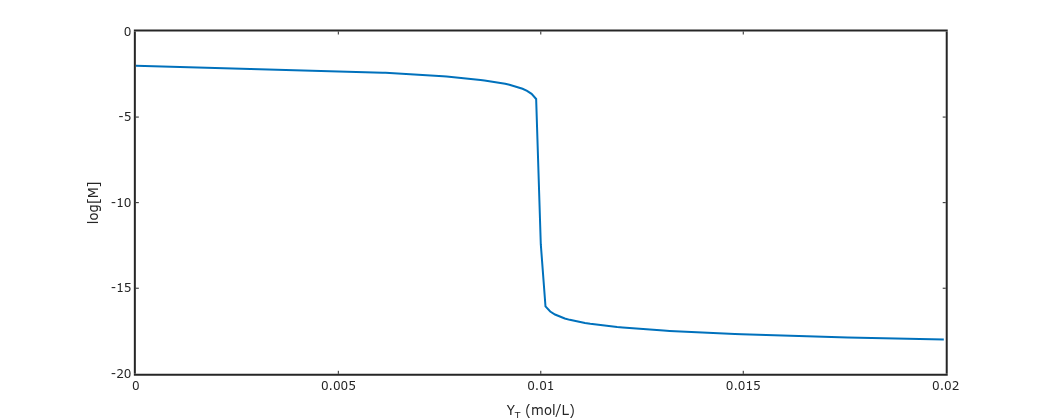

In [26]:
plot(YT,log10(M),'linewidth',2,'linewidth',2)
set(gca,'linewidth',2,'fontsize',12)
xlabel('Y_T (mol/L)'); ylabel('log[M]')

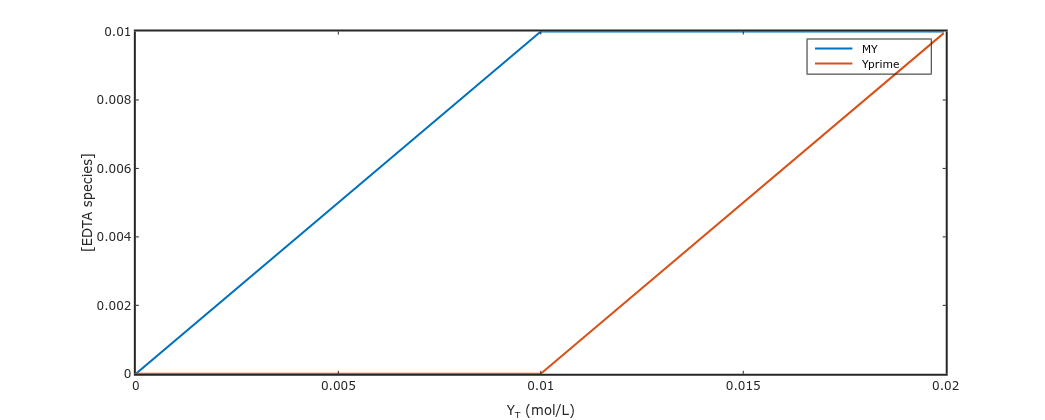

In [27]:
plot(YT,MY,'linewidth',2,YT,Yprime,'linewidth',2)
set(gca,'linewidth',2,'fontsize',12)
xlabel('Y_T (mol/L)'); ylabel('[EDTA species]')
legend('MY','Yprime')

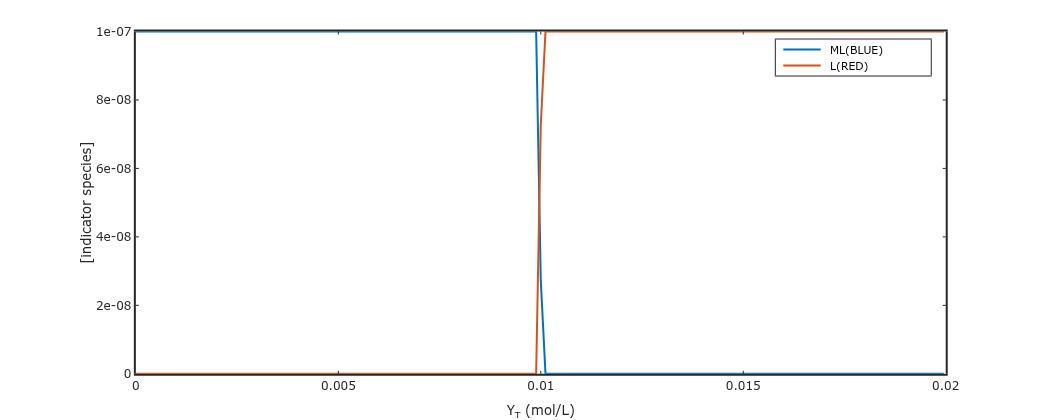

In [28]:
plot(YT,ML,'linewidth',2,YT,L,'linewidth',2)
set(gca,'linewidth',2,'fontsize',12)
xlabel('Y_T (mol/L)'); ylabel('[indicator species]')
legend('ML(BLUE)','L(RED)')